In [2]:
from collections import defaultdict
import os

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import cv2
import matplotlib.pyplot as plt

In [3]:
# Ensure that plotly renders inside the Jupyter notebook
pio.renderers.default = 'notebook_connected'

In [4]:
df = pd.read_csv("../../../db/object-detection/images.csv")
df.shape

(1032, 6)

In [5]:
df.head()

,id,name,width,height,batch,folder
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,Cam3_H243_discount_14.png,640.0,480.0,batch1_10.5,batch1
1,fc377a4c-4a15-444d-85e7-ce8a3a578a8e,Cam3_H243_discount_15.png,640.0,480.0,batch1_10.5,batch1
2,ff50bde4-3825-47b8-9cab-cc97663f1c97,Cam3_H243_discount_16.png,640.0,480.0,batch1_10.5,batch1
3,5cec4eb5-edd9-4831-9ca3-5cfb04fc6d82,Cam3_H243_discount_17.png,640.0,480.0,batch1_10.5,batch1
4,b92da22b-21df-406f-8a0b-3c3336d8393a,Cam3_H243_discount_18.png,640.0,480.0,batch1_10.5,batch1


In [6]:
names = df["name"].values

In [54]:
def extract_all_prefixes(filename):
    parts = filename.split('_')
    prefixes = []
    for i in range(1, len(parts) + 1):
        prefix = '_'.join(parts[:i])
        prefixes.append(prefix)
    return prefixes


def count_prefixes(filenames):
    prefix_counts = defaultdict(int)
    
    for filename in filenames:
        prefixes = extract_all_prefixes(filename)
        for prefix in prefixes:
            prefix_counts[prefix] += 1
    
    return prefix_counts


def build_tree(prefix_counts):
    def add_node(current_level, parts, count):
        if not parts:
            current_level["count"] = count
            return

        part = parts[0]
        if "nodes" not in current_level:
            current_level["nodes"] = []

        # Find existing node
        for node in current_level["nodes"]:
            if node["prefix"] == part:
                add_node(node, parts[1:], count)
                return

        # If not found, create a new node
        new_node = {"prefix": part, "count": count}
        current_level["nodes"].append(new_node)
        add_node(new_node, parts[1:], count)

    root = {"prefix": "", "count": 0, "nodes": []}

    for prefix, count in prefix_counts.items():
        parts = prefix.split('_')
        add_node(root, parts, count)

    # Update the root count to reflect the total number of files
    root["count"] = sum([i['count'] for i in root["nodes"]])

    return root


def tree_to_plotly_sunburst(tree):
    labels = []
    parents = []
    values = []

    def add_node(node, parent_name):
        if "nodes" in node:
            for child in node["nodes"]:
                current_name = parent_name + ('_' if parent_name else '') + child["prefix"]
                labels.append(current_name)
                parents.append(parent_name)
                values.append(child["count"])
                add_node(child, current_name)

    # Start from the top-level node (empty string prefix)
    labels.append("")
    parents.append("")
    values.append(tree["count"])

    add_node(tree[""], "")

    return labels, parents, values


# Function to print the tree
def print_tree(node, parent=None, level=0):
    prefix =f"{parent}_{node['prefix']}" if parent else node["prefix"]
    print(f"{'  ' * level}{prefix}: {node['count']}")
    
    for child in node.get("nodes", []):
        print_tree(child, prefix, level + 1)

In [55]:
# Count the prefixes
prefix_counts = count_prefixes(names)

# Build the tree
tree = build_tree(prefix_counts)

In [56]:
print_tree(tree)

: 1032
  Cam3: 418
    Cam3_H243: 19
      Cam3_H243_discount: 19
        Cam3_H243_discount_14.png: 1
        Cam3_H243_discount_15.png: 1
        Cam3_H243_discount_16.png: 1
        Cam3_H243_discount_17.png: 1
        Cam3_H243_discount_18.png: 1
        Cam3_H243_discount_19.png: 1
        Cam3_H243_discount_10.png: 1
        Cam3_H243_discount_11.png: 1
        Cam3_H243_discount_12.png: 1
        Cam3_H243_discount_13.png: 1
        Cam3_H243_discount_4.png: 1
        Cam3_H243_discount_5.png: 1
        Cam3_H243_discount_6.png: 1
        Cam3_H243_discount_7.png: 1
        Cam3_H243_discount_8.png: 1
        Cam3_H243_discount_9.png: 1
        Cam3_H243_discount_1.png: 1
        Cam3_H243_discount_2.png: 1
        Cam3_H243_discount_3.png: 1
    Cam3_H245: 60
      Cam3_H245_discount: 55
        Cam3_H245_discount_1.png: 1
        Cam3_H245_discount_2.png: 1
        Cam3_H245_discount_3.png: 1
        Cam3_H245_discount_4.png: 1
        Cam3_H245_discount_10.png: 1
        Cam3

Stopp criteria if the next level 
- only one leaf with the same number of childs
- multiple leafs and only one has more than one leafs

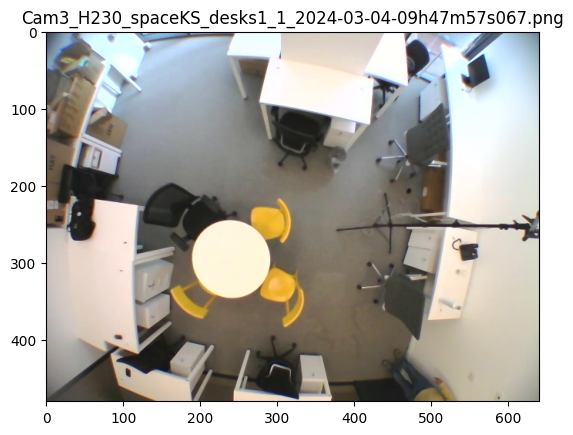

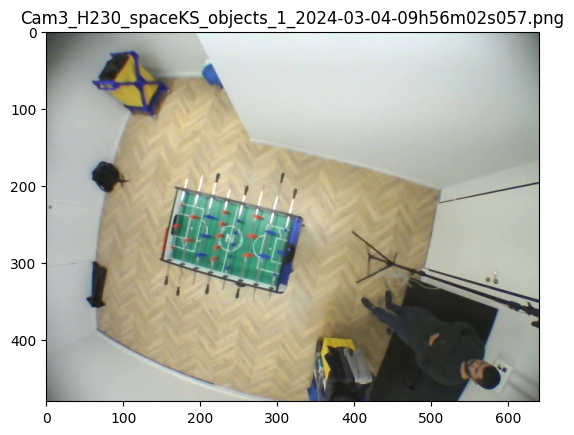

In [57]:
base_path = "../../../db/object-detection"

tmp = [
    "Cam3_H230_spaceKS_desks1_1_2024-03-04-09h47m57s067.png",
    "Cam3_H230_spaceKS_objects_1_2024-03-04-09h56m02s057.png"
]

for i in tmp:
    row = df[df["name"] == i]
    pth = os.path.join(base_path, row["batch"].iloc[0], row["folder"].iloc[0], i)
    img = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB)
    plt.figure()
    plt.imshow(img)
    plt.title(i)

Cam3_H250 - 177:
- Cam3_H250_spacesks_MR1 - 125
- Cam3_H250_spacesks_os1 - 51
- Cam3_H250_spaceKS - 1


- Cam3_H243_discount: 19
- Cam3_H245_discount: 55
- Cam3_H245_spaceKS: 5
- Cam3_H230_spaceKS_desks1: 5
- Cam3_H230_spaceKS_objects

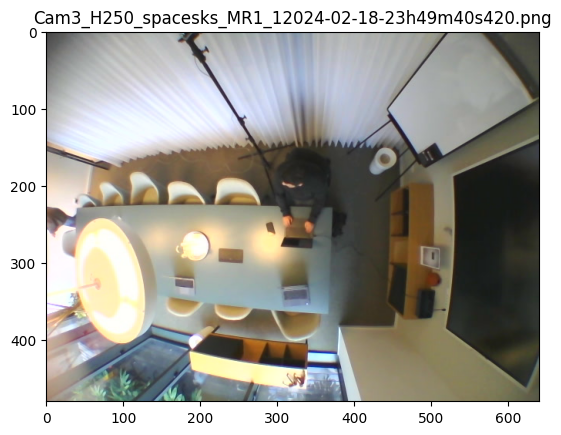

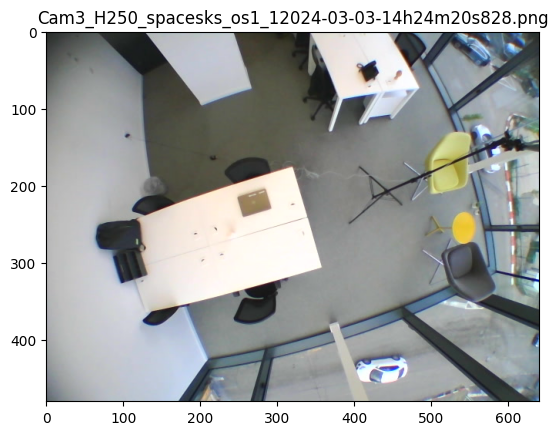

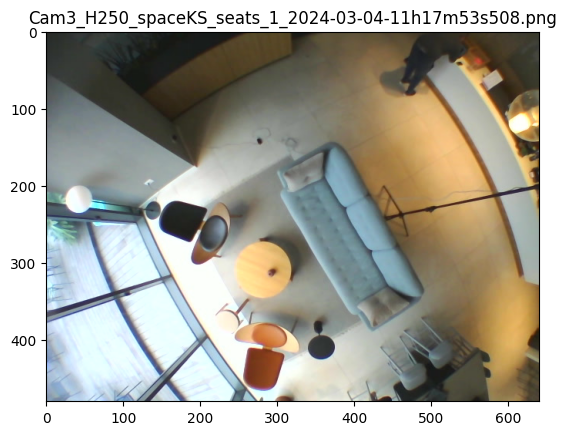

In [58]:
base_path = "../../../db/object-detection"

tmp = [
    "Cam3_H250_spacesks_MR1_12024-02-18-23h49m40s420.png",
    "Cam3_H250_spacesks_os1_12024-03-03-14h24m20s828.png",
    "Cam3_H250_spaceKS_seats_1_2024-03-04-11h17m53s508.png",
]

for i in tmp:
    row = df[df["name"] == i]
    pth = os.path.join(base_path, row["batch"].iloc[0], row["folder"].iloc[0], i)
    img = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB)
    plt.figure()
    plt.imshow(img)
    plt.title(i)

Algorithm (recursive):
1. check current node:
    1. if no child nodes return prefix
    2. if one node and 

In [ ]:
# Function to print the tree
def print_tree(node, parent=None, level=0):
    prefix =f"{parent}_{node['prefix']}" if parent else node["prefix"]
    print(f"{'  ' * level}{prefix}: {node['count']}")
    
    for child in node.get("nodes", []):
        print_tree(child, prefix, level + 1)